In [10]:

import pandas as pd
import numpy as np
from Bio.Data import CodonTable
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqUtils import seq3
import random
from Bio.SeqUtils import GC123
import multiprocessing as mp

import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager

font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['svg.fonttype']='none'


## Run deeploc  to obtain subcellular localization predictions

In [7]:
!cp ../Bradysia_coprophila/run_deeploc.py ./scripts/

In [2]:
!mkdir "$SCRATCH/extavour_lab/Everyone/Rishabh/split_fastas"

In [21]:
!mkdir /n/netscratch/extavour_lab/Everyone/Rishabh/deeploc_results

In [30]:
!cp ../Bradysia_coprophila/collembola_percent_identity_and_intron_analysis.ipynb ./

In [20]:
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta")
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [18]:
!mkdir -p "/n/netscratch/extavour_lab/Everyone/Rishabh/split_fastas"

In [21]:
##split fasta of all bcoprop longest protien isoforms to subfastas of size 10 to run deeploc in parallel
n=0
i=0
for x in fasta:
    if x not in set(result.index:
        if i%10==0:
            n+=1
        f=open(f"/n/netscratch/extavour_lab/Everyone/Rishabh/split_fastas/{n}.fasta","a")
        f.write(f">{x}"+"\n")
        f.write(str(fasta[x].seq)+"\n")
        f.close()
        i+=1

In [25]:
!sbatch scripts/deep.sh

Submitted batch job 28617471


In [14]:
##concatenate deeploc results
# List to store dataframes
dfs = []
import os
# Iterate over each file in the directory
for x in os.listdir("/n/netscratch/extavour_lab/Everyone/Rishabh/deeploc_results"):
    # for filename in os.listdir(f"deeploc_results/{x}"):
    if '.csv' in x:
        # Read CSV file into a dataframe
        df = pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/deeploc_results/{x}")
        # Append dataframe to the list
        dfs.append(df)

# Concatenate all dataframes in the list
result = pd.concat(dfs, ignore_index=True)
result=result.set_index('Protein_ID')
# result.to_csv("final_outputs/deeploc_results.csv")

In [6]:
from collections import Counter

In [6]:
result=pd.read_csv("final_outputs/deeploc_results.csv",index_col=0)

In [74]:
result.loc[list(hgts),:].to_csv("final_outputs/hgt_deeploc_results.csv")

In [7]:
locs=["Cytoplasm","Nucleus","Extracellular","Mitochondrion", "Cell membrane","Lysosome/Vacuole","Golgi apparatus","Endoplasmic reticulum","Peroxisome"]

In [8]:
locdf=pd.DataFrame(index=locs,columns=["HGT","Not-HGT"])
locdf=locdf.fillna(0)

/tmp/ipykernel_3064749/114894112.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  locdf=locdf.fillna(0)


In [9]:
for index, row in result.iterrows():
    locsi=row.Localizations.split("|")
   
    for l in locsi:
        if l in locs:
            if index in hgts:
                locdf.loc[l,"HGT"]+=1
            else:
                locdf.loc[l,"Not-HGT"]+=1

In [22]:

locdf.loc[:,"p_HGT"]=locdf.loc[:,"HGT"]/locdf.loc[:,"HGT"].sum()
locdf.loc[:,"p_Not-HGT"]=locdf.loc[:,"Not-HGT"]/locdf.loc[:,"Not-HGT"].sum()

In [23]:
locdf

,HGT,Not-HGT,p_HGT,p_Not-HGT
Cytoplasm,621,5420,0.312217,0.297492
Nucleus,430,4668,0.216189,0.256216
Extracellular,450,2587,0.226244,0.141995
Mitochondrion,61,924,0.030669,0.050716
Cell membrane,118,2258,0.059326,0.123937
Lysosome/Vacuole,85,873,0.042735,0.047917
Golgi apparatus,31,352,0.015586,0.019320
Endoplasmic reticulum,172,1029,0.086476,0.056479
Peroxisome,21,108,0.010558,0.005928


In [24]:
from scipy.stats import fisher_exact
import numpy as np

def go_enrichment_analysis(go_counts, background_counts,alternative='two-sided'):
    """
    Perform GO term enrichment analysis using Fisher's exact test.

    Args:
    go_counts (list): A list containing counts for the GO term.
    background_counts (list): A list containing counts for the background set.

    Returns:
    tuple: A tuple containing enrichment fold change and p-value.
    """
    # Check if counts contain at least two elements
    if len(go_counts) != 2 or len(background_counts) != 2:
        raise ValueError("Counts must contain exactly two elements.")

    # Perform Fisher's exact test to compute p-value
    odds_ratio, p_value = fisher_exact([go_counts, background_counts],alternative=alternative)

    # Compute fold change
    fold_change = ((go_counts[0]+1) /(np.sum(go_counts)+1)) / ((background_counts[0]+1) /(np.sum(background_counts)+1))  # Adding pseudocounts to avoid division by zero

    return fold_change, p_value

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [26]:
for index, row in locdf.iterrows():
    ##number of hgts with loc, number of hgts w/out loc
    go_counts = [row.HGT, len(hgts)-row.HGT]  # Counts for the localization of interest
    
     ##number of non-hgtswith loc, number of hgts w/out loc
    background_counts = [row["Not-HGT"], dfriso.shape[0]-len(hgts)-row["Not-HGT"]]  # Counts for the background set not in the location
    locdf.loc[index,["FC","p_value"]]=go_enrichment_analysis(go_counts, background_counts)



In [27]:
import statsmodels
from statsmodels.stats.multitest import multipletests


In [28]:
locdf['padj']=statsmodels.stats.multitest.multipletests(locdf["p_value"],method='fdr_bh')[1]
locdf.index.name='Localization'

In [29]:
locdf.to_csv("final_outputs/localization_enrichment_stats.csv")

/tmp/ipykernel_3064749/51632799.py:25: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.hlines(y_val, 0, df['FC'][i], colors=scatter.to_rgba(-np.log10(df['padj'])[i]), alpha=0.6)


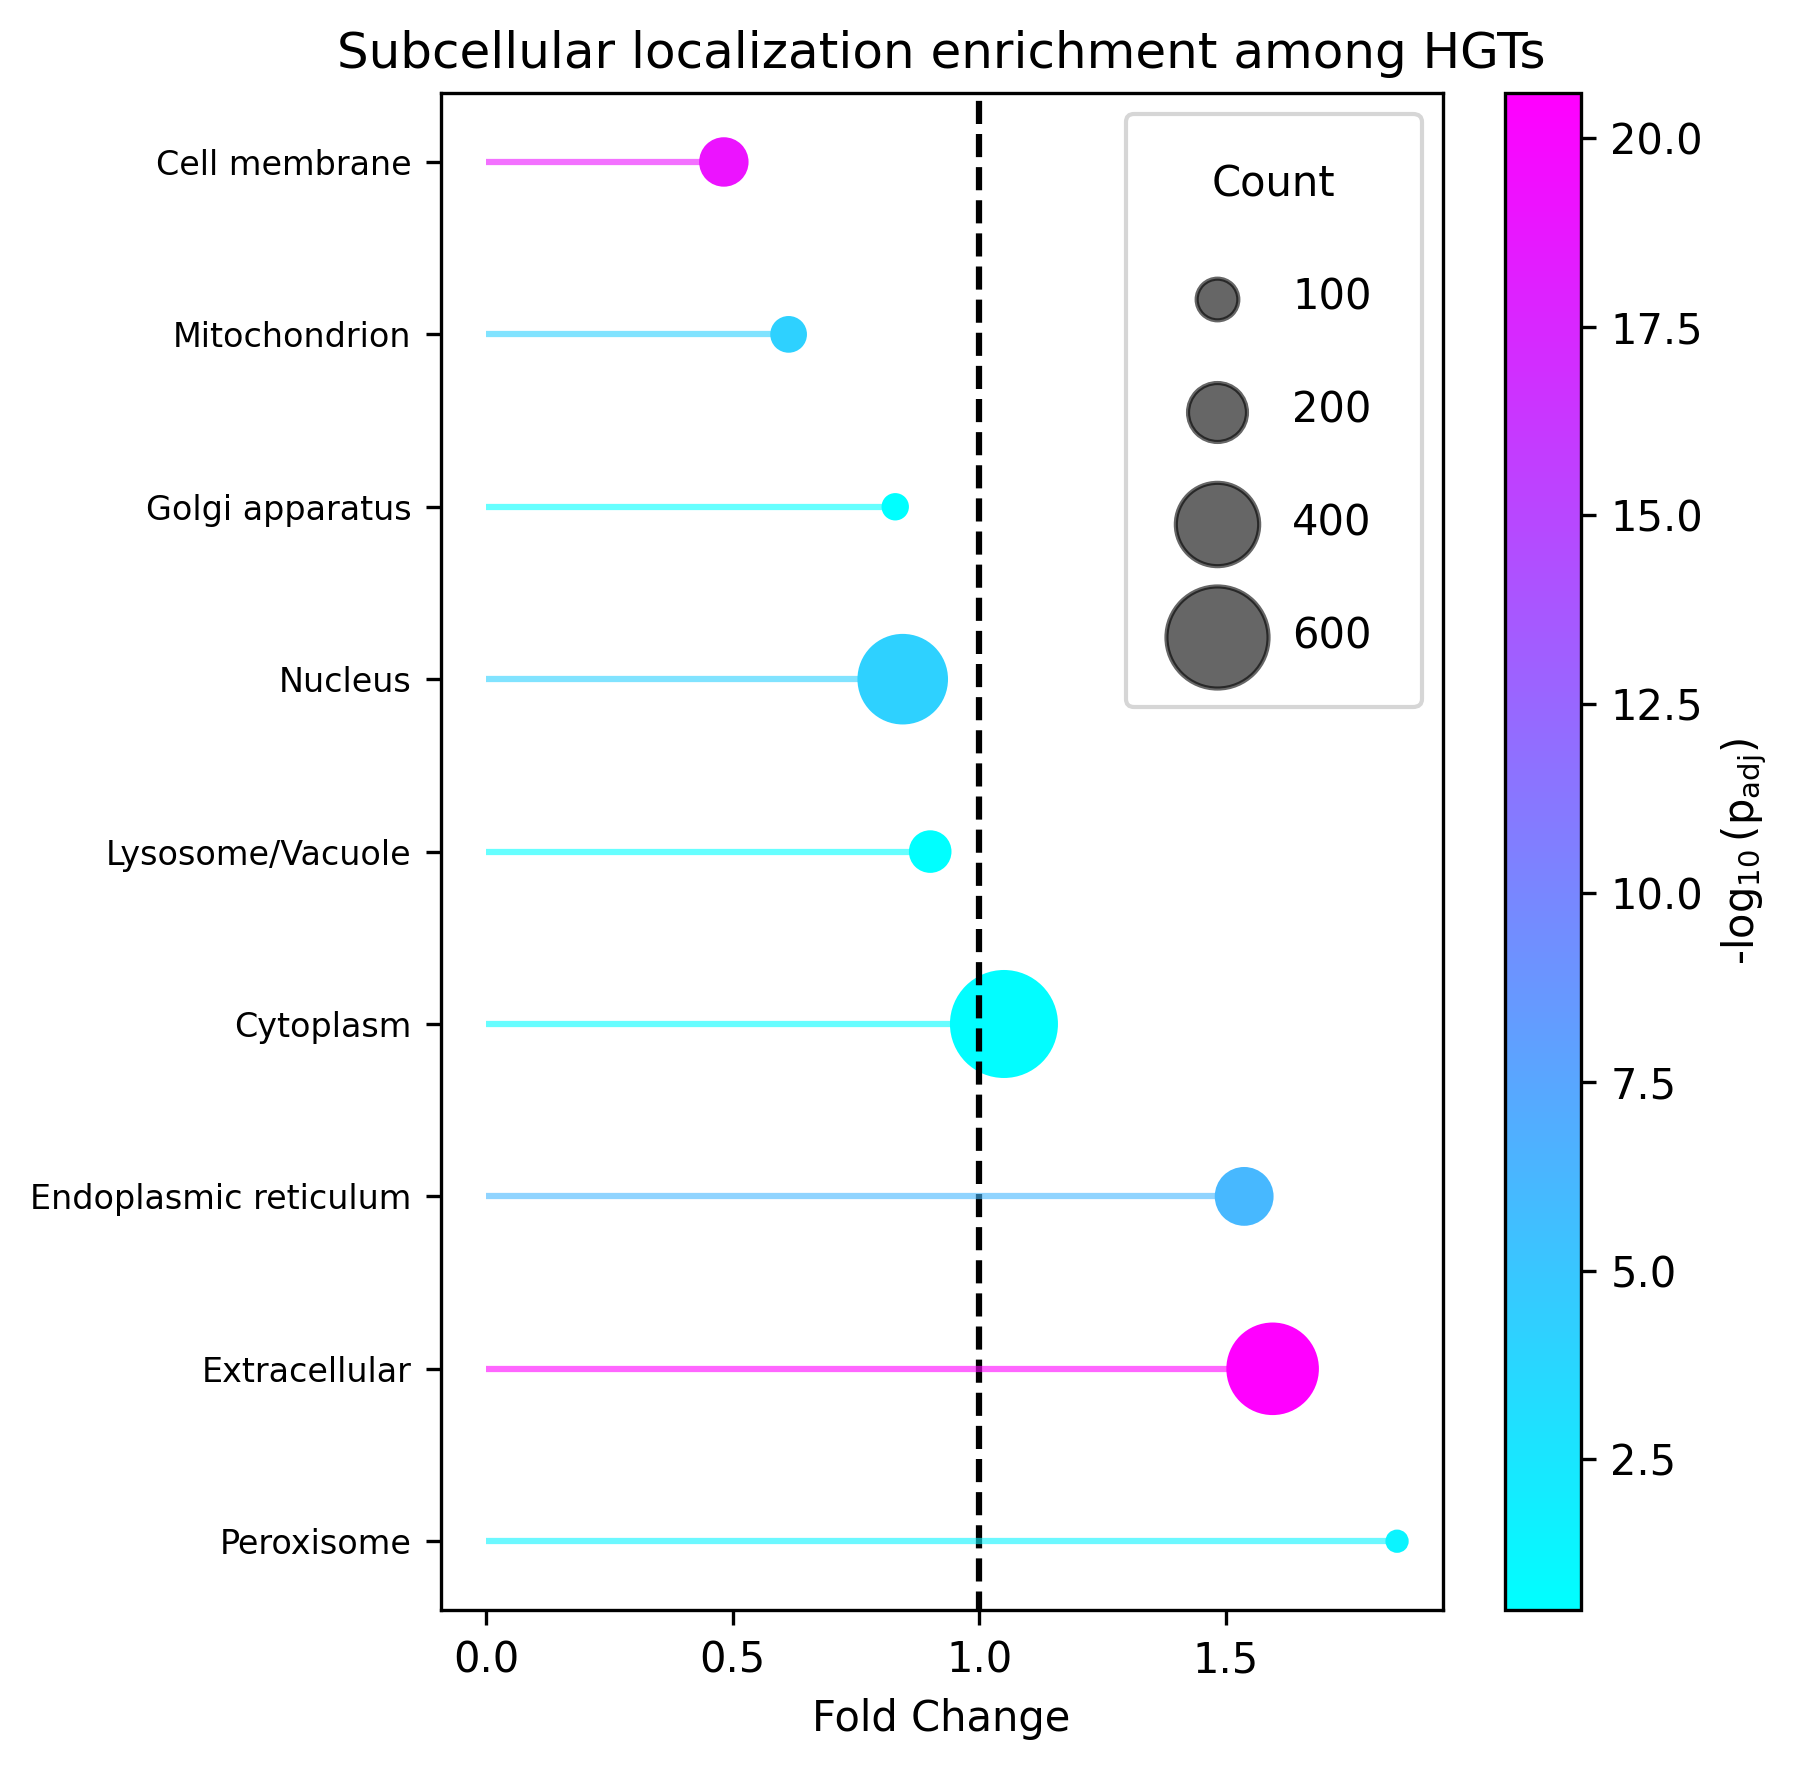

In [32]:

df=locdf.sort_values("FC",ascending=False)
plt.figure(figsize=(6, 6))  # Adjust the figure size
plt.vlines(1,-1,10,linestyle='dashed',color='black')

# Concatenate index and Name for y-axis labels
n = df.index

# Scatter plot

scatter = plt.scatter(df['FC'], n, s=df['HGT'], c=-np.log10(df['padj']), cmap='cool')

# Create dummy points for the legend
legend_sizes = [100,200,400,600]
for size in legend_sizes:
    plt.scatter([], [], s=size, label=str(size), color='black', alpha=0.6)

# Add legend
plt.legend(title='Count', scatterpoints=1, labelspacing=1.7, loc='upper right',borderpad=1.2)

# Colorbar
plt.colorbar(scatter, label=r'-$\log_{10}(\text{p}_{\text{adj}})$')

# Add horizontal lines connecting each point to y-axis
for i, y_val in enumerate(n):
    plt.hlines(y_val, 0, df['FC'][i], colors=scatter.to_rgba(-np.log10(df['padj'])[i]), alpha=0.6)

# Labels and title
plt.xlabel('Fold Change')
plt.title('Subcellular localization enrichment among HGTs')

# Adjust y-axis font size
plt.yticks(fontsize=8)  # Set font size for y-axis labels

# Adjust layout to make all ticks visible
plt.tight_layout()
plt.savefig('figures/subcellular_localization_enrichment.svg',format='svg',bbox_inches='tight')


# Show plot
plt.show()

## GO enrichment analysis

In [2]:
dfriso=pd.read_csv("final_outputs/longest_iso_data.csv",index_col=0)

In [3]:
#load a dictionary of go_term ids and attributes
f=open("go-basic.obo","r")
l=f.readlines()
go_dict={}
for x in l[27:]:
    if ":" in x:
        xl=x.split(": ")[1]
        xl=xl.strip()
        if 'id: ' in x:
          id=xl
          go_dict[id]={}
        key=x.split(": ")[0]
        key=key.strip()
        go_dict[id][key]=xl

In [4]:

godf=pd.read_csv("ncbi_dataset/data/GCF_014529535.1/GCF_014529535.1_BU_Bcop_v1_gene_ontology.gaf.tsv.gaf",sep="\t",index_col=0,comment="!",header=None)

In [5]:
for index, row in dfriso.iterrows():
    gene=row['gene']
    gi=godf[godf[2]==gene]
    if gi.shape[0]>0:
        di={"F":[],"P":[],"C":[]}
        for index2, row in gi.iterrows():
            c=row[8]
            go=row[4]
            name=go_dict[go]['name']
            s=f"{go}:{name}"
            l=di[c]
            l.append(s)
            di[c]=l
        for x in di:
            dfriso.loc[index,x]=str(di[x])
            


In [8]:
h=dfriso[dfriso.tree_HGT]
h=h[h.P!='[]']
h.shape[0]

1187

In [33]:
transposon_terms="GO:0006310|GO:0015074|GO:0006313|GO:0098039|GO:0098038|GO:0006317|GO:0006318|GO:0032197"

In [35]:
h[h.P.astype(str).str.contains(transposon_terms)].shape[0]

38

In [36]:
## percentage of biological process terms possibly associated with transposons
38/1187

0.03201347935973041

In [43]:
h=dfriso[dfriso.tree_HGT].loc[:,['description','F','P']]

h.description=[" ".join(x.replace(" [Bradysia coprophila]","").split(" ")[1:]) for x in h.description]
h['F']=[str(x).replace("[","").replace("]","").replace("'","").replace("nan","") for x in h['F']]
h['P']=[str(x).replace("[","").replace("]","").replace("'","").replace("nan","") for x in h['P']]
h.columns=['description','GO molecular function','GO biological process']
h.to_csv("final_outputs/hgt_go_terms.csv")

In [44]:
##tabulate hgt gene count per go_term 
from collections import Counter
hgts=set(dfriso[dfriso.tree_HGT].gene)
hgtgo=list(godf[godf[2].isin(hgts)][4])
m=set(Counter(hgtgo))
hgtdf = pd.DataFrame(index=list(m))
for index, row in hgtdf.iterrows():
  hgtdf.loc[index,"Name"]=go_dict[index]['name']
  hgtdf.loc[index,"Component"]=go_dict[index]['namespace']

In [45]:
for index, row in hgtdf.iterrows():
  total_genes=list(set(godf[godf[4]==index][2]))
  hgt_genes=list(dfriso[(dfriso.tree_HGT)&(dfriso.gene.isin(total_genes))].gene)
  desc=str(list(dfriso[dfriso.gene.isin(hgt_genes)].description))
  hgtdf.loc[index,"genes"]=str(hgt_genes)
  hgtdf.loc[index,"genes_desc"]=desc
  hgtdf.loc[index,"Total_count"]=len(total_genes)
  hgtdf.loc[index,"HGT_count"]=len(hgt_genes)


In [46]:
all_hgt_genes=set(dfriso[dfriso.tree_HGT].gene)
len(all_hgt_genes)

1627

In [47]:
##molecular function enrichment
##number of hgts with any go term 
n_hgts_with_go=len(set(godf[(godf[8]=='F')&(godf[2].isin(all_hgt_genes))][2]))
##number of non-hgts with any go term
n_non_hgts_with_go=len(set(godf[(godf[8]=='F')&~(godf[2].isin(all_hgt_genes))][2]))
mfdf=hgtdf[hgtdf.Component=="molecular_function"]
for index, row in mfdf.iterrows():
  ##number of hgts with specific go term, number hgts without term
  go_counts = [row.HGT_count, n_hgts_with_go-row.HGT_count]  # Counts for the GO term of interest
  #number of non hgts with specific go term, number non hgts  without term
  background_counts = [row.Total_count-row.HGT_count,n_non_hgts_with_go-(row.Total_count-row.HGT_count)]  # Counts for the background set (total non hgt, total 
  mfdf.loc[index,["FC","p_value"]]=go_enrichment_analysis(go_counts, background_counts, alternative='greater')
mfdf['padj']=statsmodels.stats.multitest.multipletests(mfdf["p_value"],method='fdr_bh')[1]

mfdf.index.name='GO term'
mfdf=mfdf.sort_values('HGT_count',ascending=False)
mfdf.to_csv('final_outputs/molecular_function_enrichment.tsv',sep='\t')

/tmp/ipykernel_3064749/3362201370.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mfdf['padj']=statsmodels.stats.multitest.multipletests(mfdf["p_value"],method='fdr_bh')[1]


/tmp/ipykernel_3064749/4131338518.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.hlines(y_val, 0, dfi['FC'][i], colors=scatter.to_rgba(-np.log10(dfi['padj'])[i]), alpha=0.6)


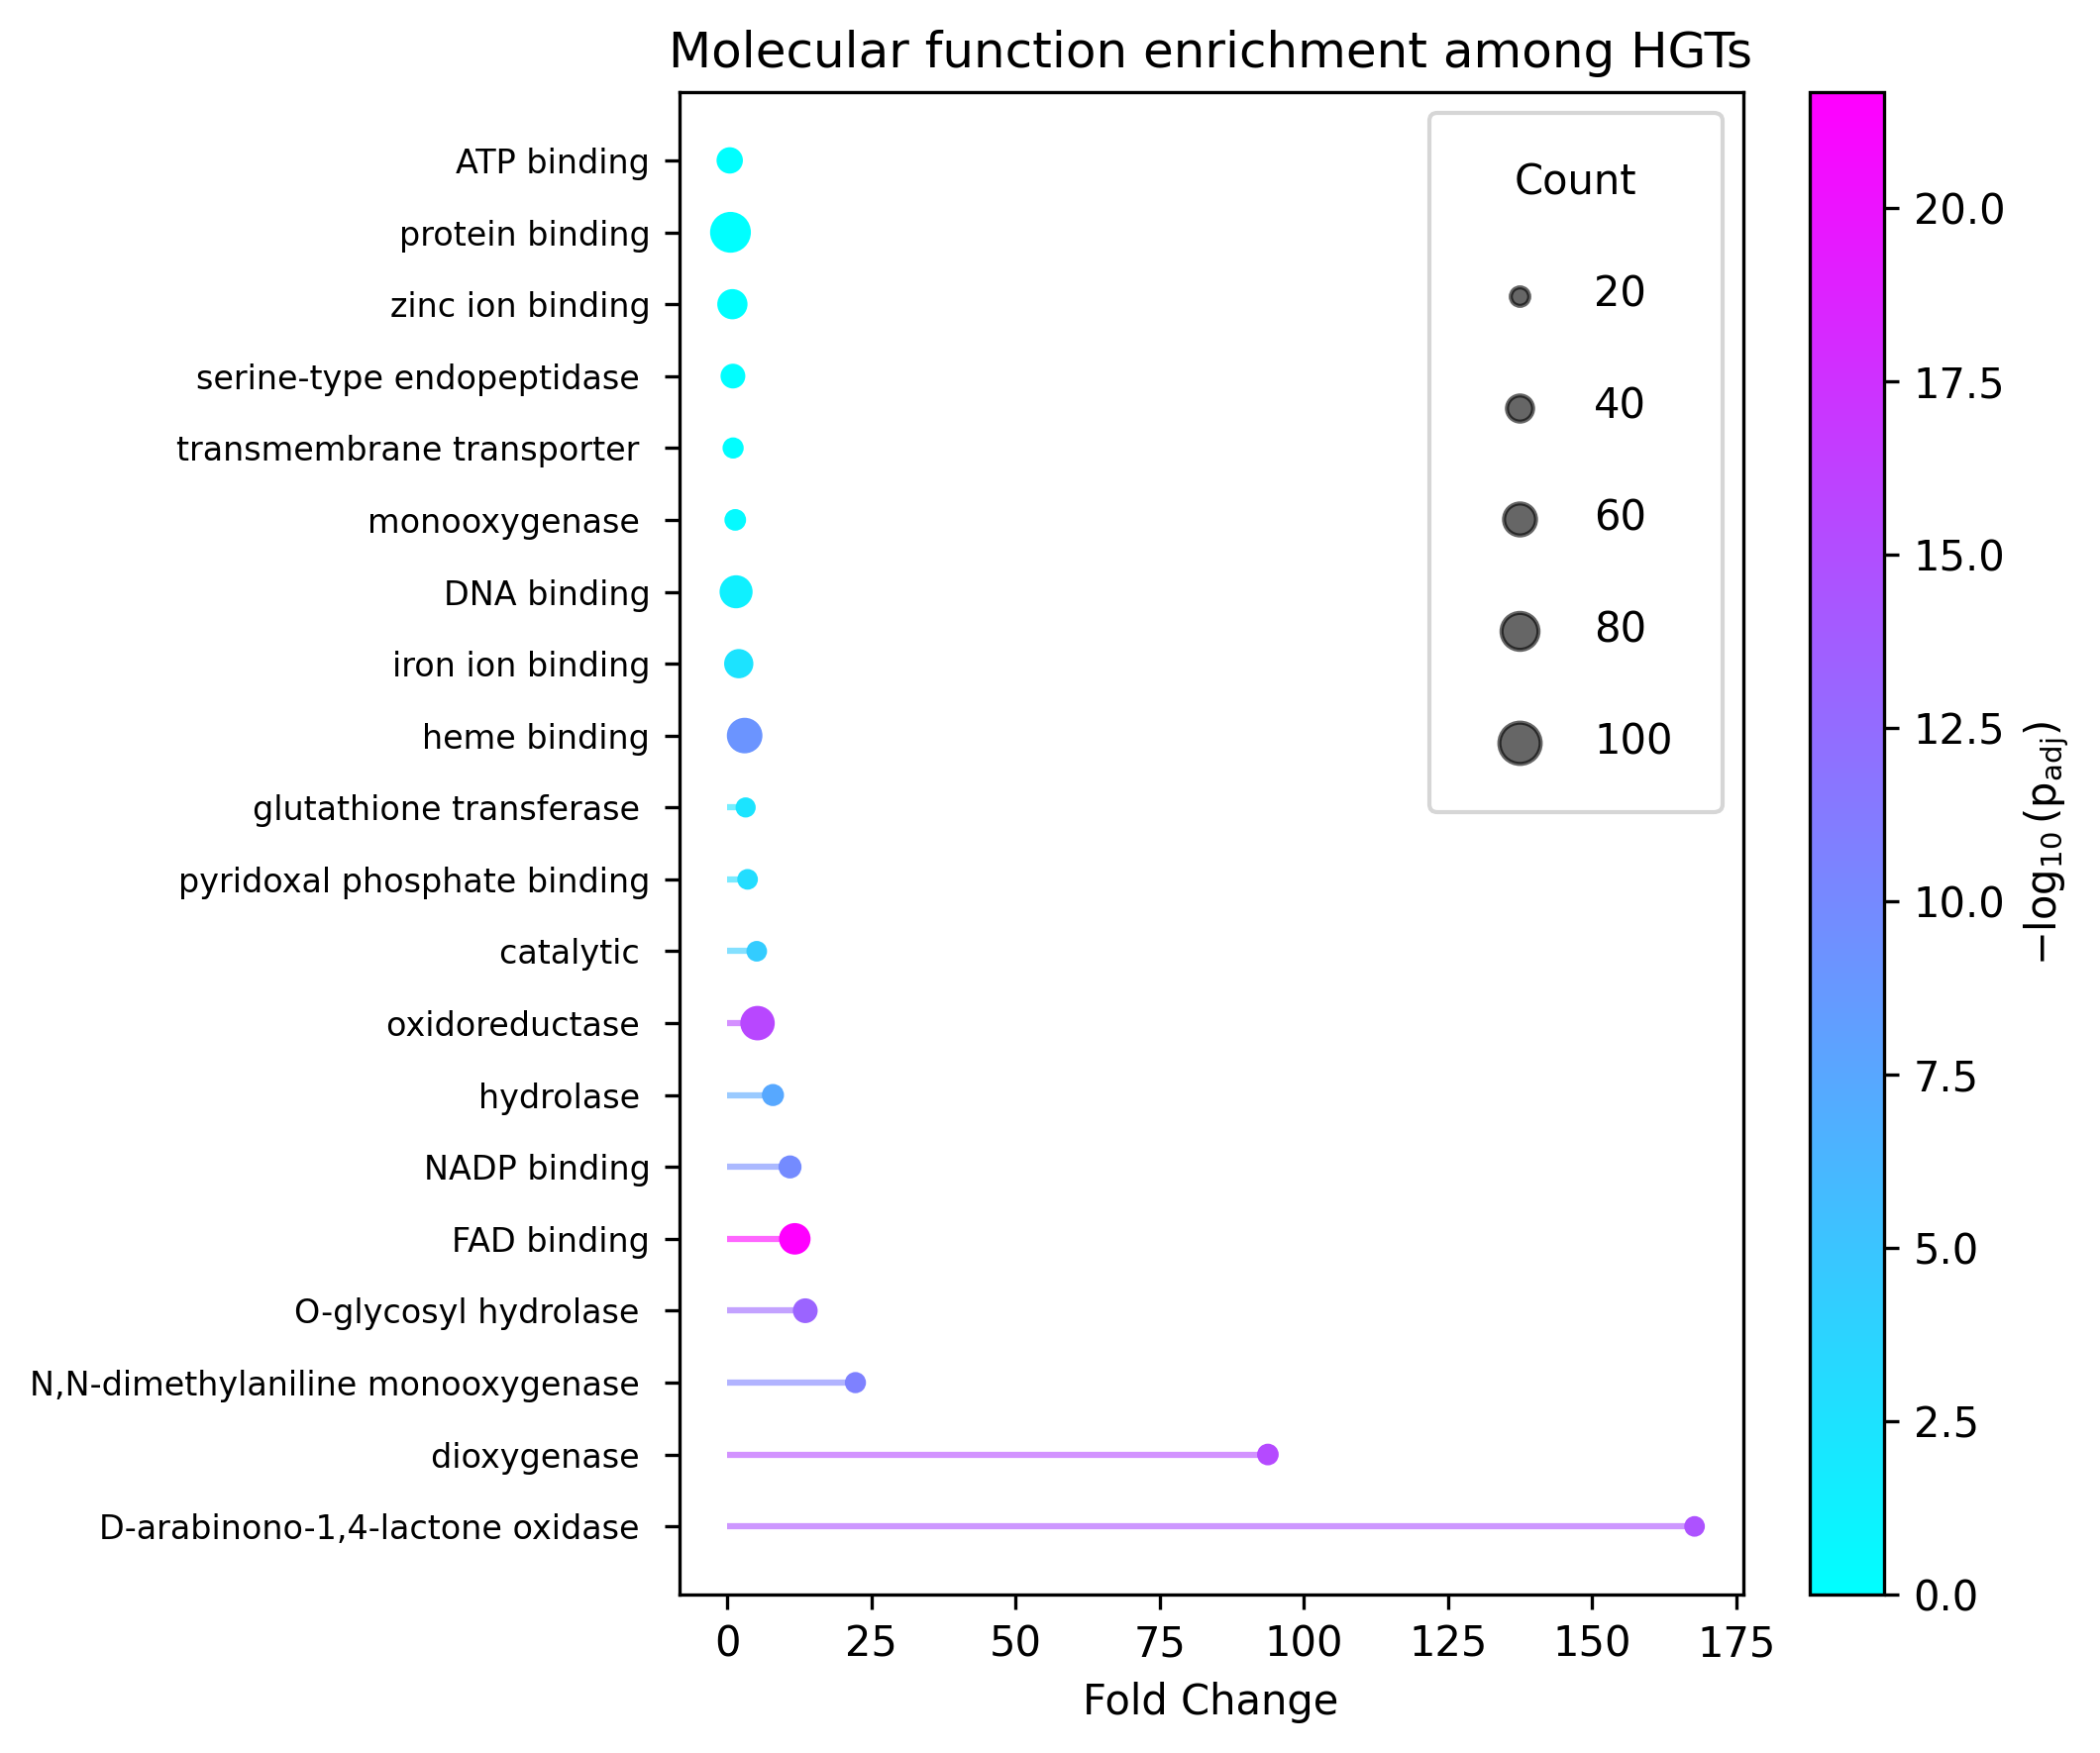

In [62]:
dfi=mfdf.sort_values("HGT_count",ascending=False).iloc[0:22,:].sort_values('FC',ascending=False)
dfi=dfi[~(dfi.Name.str.contains("paired donors")|dfi.Name.str.contains("flavin"))|dfi.Name.str.contains('CH-OH')]
dfi.Name=dfi.Name.replace('hydrolase activity, hydrolyzing O-glycosyl compounds','O-glycosyl hydrolase activity')
dfi.Name=[x.replace('activity','') for x in dfi.Name]


plt.figure(figsize=(7, 6)) # Adjust the figure size


# Concatenate index and Name for y-axis labels
n = [y for x,y in zip (dfi.index,dfi.Name)]

# Scatter plot
ymin,ymax=plt.ylim()

scatter = plt.scatter(dfi['FC'], n, s=dfi['HGT_count'], c=-np.log10(dfi['padj']), cmap='cool')

# Create dummy points for the legend
legend_sizes = [20,40,60,80,100]
for size in legend_sizes:
    plt.scatter([], [], s=size, label=str(size), color='black', alpha=0.6)

# Add legend
plt.legend(title='Count', scatterpoints=1, labelspacing=1.7, loc='upper right',borderpad=1.2)

# Colorbar
plt.colorbar(scatter, label=r'$-\log_{10}(\text{p}_{\text{adj}})$')

# Add horizontal lines connecting each point to y-axis
for i, y_val in enumerate(n):
    plt.hlines(y_val, 0, dfi['FC'][i], colors=scatter.to_rgba(-np.log10(dfi['padj'])[i]), alpha=0.6)

# Labels and title
plt.xlabel('Fold Change')
plt.title('Molecular function enrichment among HGTs')

# Adjust y-axis font size
plt.yticks(fontsize=8)  # Set font size for y-axis labels

# Adjust layout to make all ticks visible
plt.tight_layout()
plt.savefig('figures/molecular_function_enrichment.svg',format='svg',bbox_inches='tight')

# Show plot
plt.show()

In [61]:
##number of hgts with any go term 
n_hgts_with_go=len(set(godf[(godf[8]=='P')&(godf[2].isin(all_hgt_genes))][2]))
##number of non-hgts with any go term
n_non_hgts_with_go=len(set(godf[(godf[8]=='P')&~(godf[2].isin(all_hgt_genes))][2]))
bpdf=hgtdf[hgtdf.Component=="biological_process"]
for index, row in bpdf.iterrows():
  ##number of hgts with specific go term, number hgts without term
  go_counts = [row.HGT_count, n_hgts_with_go-row.HGT_count]  # Counts for the GO term of interest
  #number of non hgts with specific go term, number non hgts  without term
  background_counts = [row.Total_count-row.HGT_count,n_non_hgts_with_go-(row.Total_count-row.HGT_count)]  # Counts for the background set (total non hgt, total 
  bpdf.loc[index,["FC","p_value"]]=go_enrichment_analysis(go_counts, background_counts, alternative='greater')
bpdf['padj']=statsmodels.stats.multitest.multipletests(bpdf["p_value"],method='fdr_bh')[1]

bpdf.index.name='GO term'
bpdf=bpdf.sort_values('HGT_count',ascending=False)
bpdf.to_csv('final_outputs/biological_process_enrichment.tsv',sep='\t')

/tmp/ipykernel_3064749/650773369.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bpdf['padj']=statsmodels.stats.multitest.multipletests(bpdf["p_value"],method='fdr_bh')[1]


/tmp/ipykernel_3064749/495220829.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.hlines(y_val, 0, dfi['FC'][i], colors=scatter.to_rgba(-np.log10(dfi['padj'])[i]), alpha=0.6)


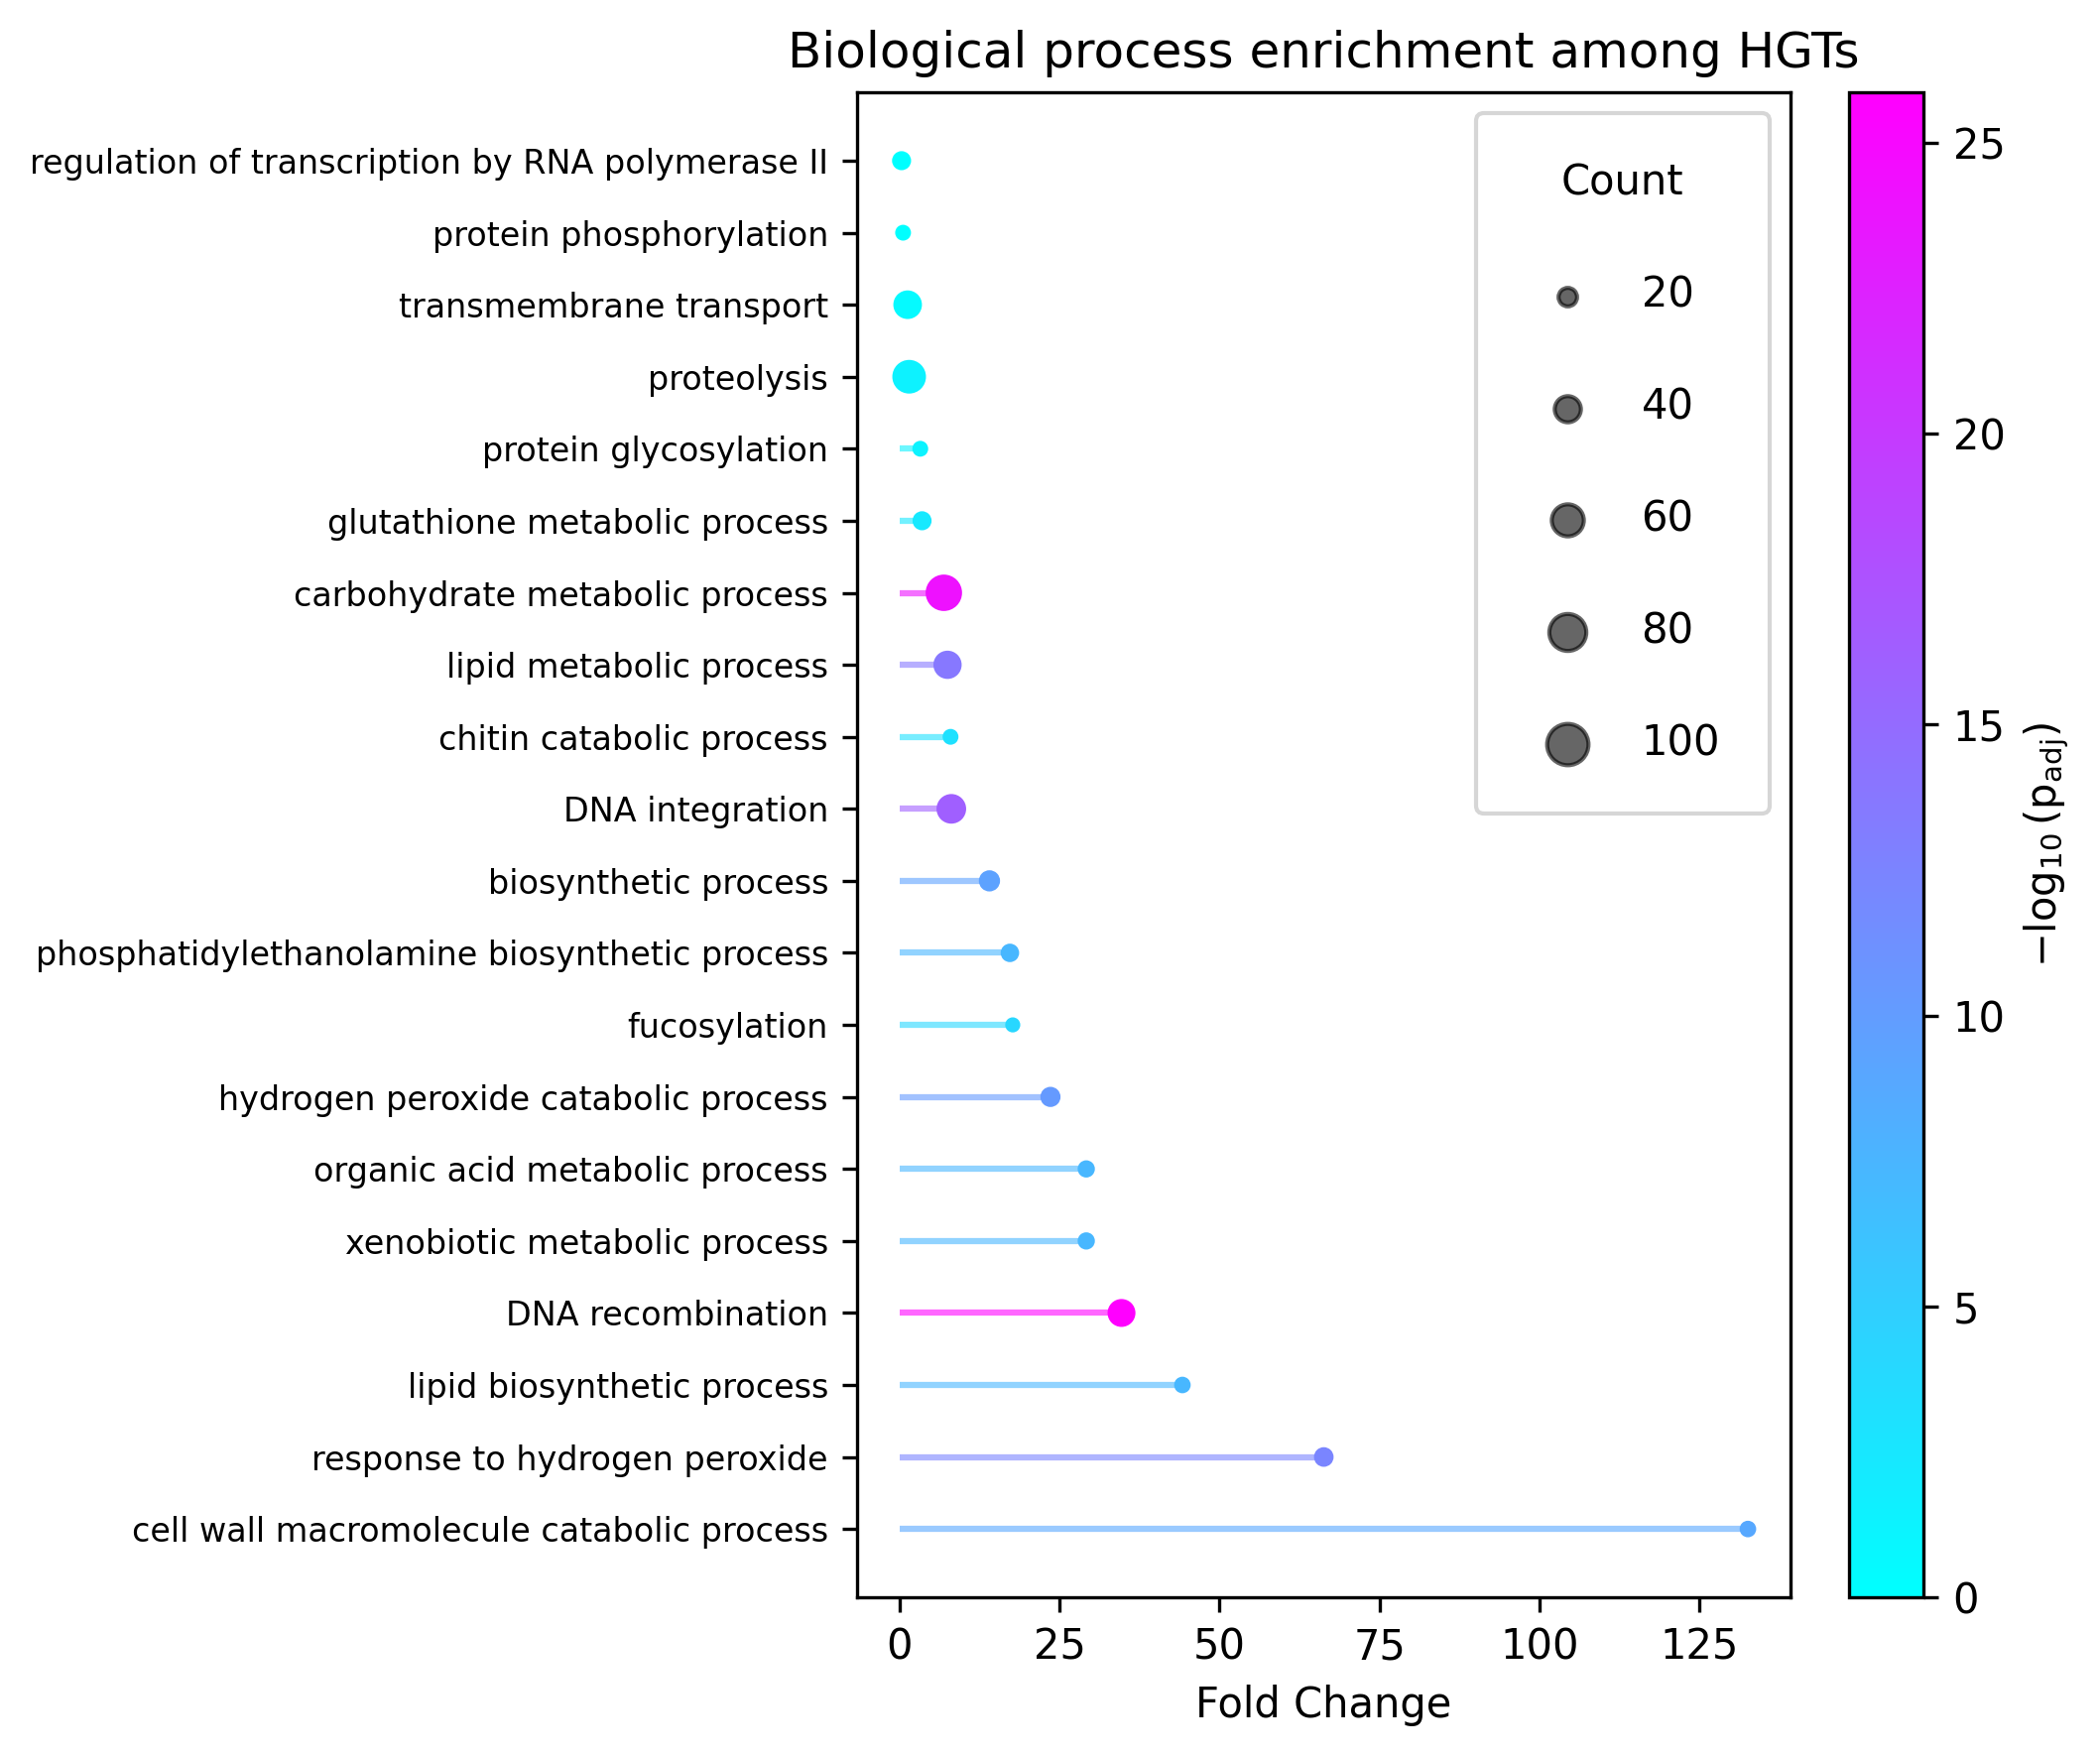

In [67]:
dfi=bpdf.sort_values("HGT_count",ascending=False).iloc[0:20,:].sort_values('FC',ascending=False)
dfi=dfi[~(dfi.Name.str.contains("paired donors")|dfi.Name.str.contains("flavin"))]
dfi.Name=dfi.Name.replace('hydrolase activity, hydrolyzing O-glycosyl compounds','O-glycosyl hydrolase activity')
dfi.Name=[x.replace('activity','') for x in dfi.Name]


plt.figure(figsize=(7, 6)) # Adjust the figure size


# Concatenate index and Name for y-axis labels
n = [y for x,y in zip (dfi.index,dfi.Name)]

# Scatter plot
ymin,ymax=plt.ylim()

scatter = plt.scatter(dfi['FC'], n, s=dfi['HGT_count'], c=-np.log10(dfi['padj']), cmap='cool')

# Create dummy points for the legend
legend_sizes = [20,40,60,80,100]
for size in legend_sizes:
    plt.scatter([], [], s=size, label=str(size), color='black', alpha=0.6)

# Add legend
plt.legend(title='Count', scatterpoints=1, labelspacing=1.7, loc='upper right',borderpad=1.2)

# Colorbar
plt.colorbar(scatter, label=r'$-\log_{10}(\text{p}_{\text{adj}})$')

# Add horizontal lines connecting each point to y-axis
for i, y_val in enumerate(n):
    plt.hlines(y_val, 0, dfi['FC'][i], colors=scatter.to_rgba(-np.log10(dfi['padj'])[i]), alpha=0.6)

# Labels and title
plt.xlabel('Fold Change')
plt.title('Biological process enrichment among HGTs')

# Adjust y-axis font size
plt.yticks(fontsize=8)  # Set font size for y-axis labels

# Adjust layout to make all ticks visible
plt.tight_layout()
plt.savefig('figures/biological_process_enrichment.svg',format='svg',bbox_inches='tight')


# Show plot
plt.show()

## Comparison to carbohydrate-active enzyme data and salivary proteomics from Monesi et al.  DOI: 10.1016/j.isci.2023.106449


In [1]:
import pandas as pd

In [46]:
manual=pd.read_csv("final_outputs/tree_manual_inspection/manual_inspection_results_with_merging.tsv",sep="\t",index_col=0)

In [47]:
gene=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
gene=gene[gene[2]=='CDS']
gmap={x.split(";")[0].replace("ID=cds-",""):x.split("locus_tag=")[1].split(";")[0] for x in gene[8]}
rgmap={x.split("locus_tag=")[1].split(";")[0]:x.split(";")[0].replace("ID=cds-","") for x in gene[8]}

In [30]:
##P. hygida orthologs to b. coprophila hgts
import ast
phyg_prots=[]
for index, row in manual[manual.HGT].iterrows():
    phyg_prots.extend([x for x in ast.literal_eval(row.sciarid_seqs) if 'KAJ' in x])

In [31]:
## percent of p.hygida proteome (Table S10.)
prot=pd.read_csv("Pseudolycoriella_hygida_data/phyg_proteome.tsv",sep="\t",index_col=0)
prot['prot']=[rgmap[x.split("-")[0]] for x in prot.index]
len(set(prot.prot)&set(phyg_prots)),prot.shape[0],len(set(prot.prot)&set(phyg_prots))/prot.shape[0]

(129, 1149, 0.1122715404699739)

In [66]:
prot=prot[prot.prot.isin(set(phyg_prots))]
for index, row in prot.iterrows():
  
    os=manual[manual.sciarid_seqs.str.contains(row['prot'])].coprophila_seqs.values
    orthologs=set()
    for x in os:
        orthologs=orthologs|set(ast.literal_eval(x))
    prot.loc[index,'B.copro_orthologs']=str(orthologs).replace("{","").replace("}","").replace("'","")
prot=prot.loc[:,['Name','prot','B.copro_orthologs','Unique peptides']]
prot.to_csv("final_outputs/p_hygida_proteome.tsv",sep='\t')

In [2]:
dfriso=pd.read_csv("final_outputs/longest_iso_data.csv",index_col=0)

hgts=set(dfriso[dfriso.tree_HGT].gene)


In [95]:
## load bcopro predicted cazymes from Monesi table S9
cazy=pd.read_csv('Pseudolycoriella_hygida_data/bcopro_cazy.tsv',sep='\t',index_col=0)
gff=pd.read_csv("ncbi_dataset/data/GCF_014529535.1/genomic.gff",sep="\t",comment="#",header=None)
def get_gene(x):
    return gff[gff[8].str.contains(x)].iloc[0,8].split(";gene=")[1].split(";")[0]
cazy['gene']=[get_gene(x) for x in cazy.index]
hgt_cazy=cazy[cazy.gene.isin(hgts)]
for index, row in hgt_cazy.iterrows():
    hgt_cazy.loc[index,'protein']=dfriso[dfriso.gene==row.gene].index.values
hgt_cazy=hgt_cazy.set_index("protein")
# hgt_cazy=pd.read_csv("final_outputs/predicted_cazymes.csv",index_col=0)
## get rid of non-cazymes
hgt_cazy[hgt_cazy['CAZy family']!=' - '].shape[0]

/tmp/ipykernel_1903202/1475648558.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hgt_cazy.loc[index,'protein']=dfriso[dfriso.gene==row.gene].index.values


98

In [29]:

hgt_cazy[hgt_cazy['CAZy family']!=' - '].to_csv("final_outputs/predicted_cazymes.csv")

In [5]:

cazy[cazy['CAZy family']!=' - '].shape[0]

270

In [ ]:
##load experimentally-validated p.lycoriella HGTs from monesi et al

In [72]:
gene=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
gene=gene[gene[2]=='CDS']
gmap={x.split(";")[0].replace("ID=cds-",""):x.split("locus_tag=")[1].split(";")[0] for x in gene[8]}
rgmap={x.split("locus_tag=")[1].split(";")[0]:x.split(";")[0].replace("ID=cds-","") for x in gene[8]}

In [68]:
phyg_gene={gmap[x] for x in phyg_prots}

In [78]:
mcon=pd.read_csv('Pseudolycoriella_hygida_data/monesi_confirmed_cazys.tsv',sep='\t')
print(mcon.shape[0])
mcon['Protein']=[x.split("-")[0] for x in mcon.Protein]
dfr=mcon[mcon['Protein'].isin(phyg_gene)]

18


In [82]:
dfr['Protein']=[rgmap[x] for x in dfr.Protein]
for index, row in dfr.iterrows():
  
    os=manual[manual.sciarid_seqs.str.contains(row['Protein'])].coprophila_seqs
    orthologs=set()
    for x in os:
        orthologs=orthologs|set(ast.literal_eval(x))
    dfr.loc[index,'B.copro_orthologs']=str(orthologs).replace("{","").replace("}","").replace("'","")

/tmp/ipykernel_1903202/3467383671.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfr['Protein']=[rgmap[x] for x in dfr.Protein]
/tmp/ipykernel_1903202/3467383671.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfr.loc[index,'B.copro_orthologs']=str(orthologs).replace("{","").replace("}","").replace("'","")


In [75]:
dfr.columns=['P.hygida_protein', 'Annotation', 'EC Number', 'CAZy family', 'Substrate',
       'Activity', 'B.copro_orthologs']
dfr=dfr.loc[:,['P.hygida_protein', 'B.copro_orthologs', 'Annotation', 'EC Number', 'CAZy family', 'Substrate', "Activity"]]
dfr.to_csv("final_outputs/confirmed_cazymes.tsv",sep="\t")

In [3]:
dfr.shape[0]

12

In [6]:
## fill in digestive enzyme information to differential expression data

In [1]:
import pandas as pd

In [7]:
m=pd.read_csv("final_outputs/manual_annotation_v4.csv")

In [8]:
h=pd.read_csv('final_outputs/salivary_upregulated_hgts.csv',index_col=0)
prot=set(m[m.manual_pathway.str.contains('Protein catabolism')].prot)
lipid=set(m[m.manual_pathway.str.contains('Lipid catabolism')].prot)
cazymes=set(pd.read_csv("final_outputs/predicted_cazymes.csv", index_col=0).index)
h['CAZymes']=h.protein.isin(cazymes)
h['protein_catabolism']=h.protein.isin(prot)
h['lipid_catabolism']=h.protein.isin(lipid)
h[h.CAZymes|h.protein_catabolism|h.lipid_catabolism].shape[0]

12

In [9]:
h.to_csv('final_outputs/salivary_upregulated_hgts.csv')

In [10]:
h=pd.read_csv("final_outputs/p_hygida_proteome.tsv",sep='\t',index_col=0)

In [11]:
h['CAZymes']=h['B.copro_orthologs'].str.contains("|".join(cazymes))
h['protein_catabolism']=h['B.copro_orthologs'].str.contains("|".join(prot))
h['lipid_catabolism']=h['B.copro_orthologs'].str.contains("|".join(lipid))

In [12]:
h[h.CAZymes|h.protein_catabolism|h.lipid_catabolism].shape[0]

32

In [13]:
h.to_csv("final_outputs/p_hygida_proteome.tsv",sep='\t')